# Math 465 Fall 2026

## Module 4. Demo: Spectral clustering

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu

This notebook demonstrates:

- a failure case for $k$-means on two moons;
- construction of a neighborhood graph and its normalized Laplacian;
- spectral coordinates and clustering;
- the effect of the number of neighbors.

True labels are used only to color plots and evaluate accuracy. The graph and clustering are computed without them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.neighbors import kneighbors_graph
from scipy.linalg import eigh
from scipy.sparse.csgraph import connected_components

random_state = 2026


### Example 1. Spectral clustering on two moons

#### Generate data and apply $k$-means

Ordinary $k$-means assigns points to their nearest centroid. These assignments need not follow the curved shape of each moon.

k-means accuracy in original coordinates: 0.757


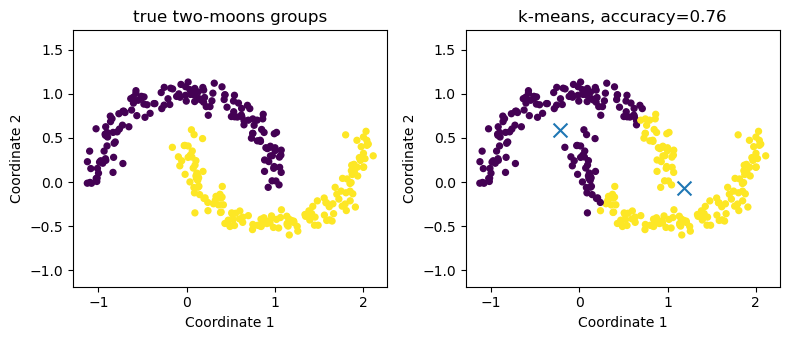

In [2]:
X, labels = make_moons(n_samples=300, noise=0.08, random_state=random_state)

kmeans_raw = KMeans(n_clusters=2, n_init=20, random_state=random_state)
labels_kmeans = kmeans_raw.fit_predict(X)

acc_kmeans = max(
    np.mean(labels_kmeans == labels),
    np.mean(1 - labels_kmeans == labels),
)
print(f"k-means accuracy in original coordinates: {acc_kmeans:.3f}")

if np.mean(labels_kmeans == labels) < 0.5:
    labels_kmeans = 1 - labels_kmeans

plt.figure(figsize=(8, 3.5))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", vmin=0, vmax=1, s=18)
plt.axis('equal')
plt.xlabel('Coordinate 1')
plt.ylabel('Coordinate 2')
plt.title('true two-moons groups')

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=labels_kmeans, cmap="viridis", vmin=0, vmax=1, s=18)
plt.scatter(kmeans_raw.cluster_centers_[:,0], kmeans_raw.cluster_centers_[:,1], marker='x', s=100)
plt.axis('equal')
plt.xlabel('Coordinate 1')
plt.ylabel('Coordinate 2')
plt.title(f'k-means, accuracy={acc_kmeans:.2f}')
plt.tight_layout()
plt.show()


#### construct a symmetric $k$-nearest-neighbor graph

The graph should follow the local geometry of each moon. We use the union symmetrization: connect $i$ and $j$ if either point lists the other among its $k$ nearest neighbors.


In [3]:
k = 8
A_knn = kneighbors_graph(X, n_neighbors=k, mode='connectivity', include_self=False)
W = A_knn.maximum(A_knn.T).toarray()

d = W.sum(axis=1)
print(f"minimum degree = {d.min():.0f}, maximum degree = {d.max():.0f}")
print(f"number of undirected edges = {int(W.sum()/2)}")

n_components = connected_components(W, directed=False, return_labels=False)
print(f"connected components = {n_components}")


minimum degree = 8, maximum degree = 15
number of undirected edges = 1440
connected components = 1


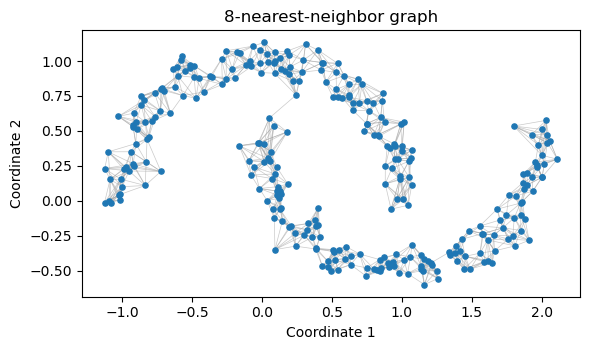

In [4]:
def plot_graph(X, W, ax, title):
    ii, jj = np.where(np.triu(W, 1) > 0)
    segments = np.stack([X[ii], X[jj]], axis=1)
    ax.add_collection(LineCollection(segments, colors='0.65', linewidths=0.5,
                                     alpha=0.6, zorder=1))
    ax.scatter(X[:, 0], X[:, 1], s=14, color='tab:blue', zorder=2)
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2', title=title)
    ax.set_aspect('equal', adjustable='box')

fig, ax = plt.subplots(figsize=(6, 4))
plot_graph(X, W, ax, f'{k}-nearest-neighbor graph')
plt.tight_layout()
plt.show()


#### Normalized graph Laplacian and its small eigenvalues

We form

$$L_{\rm sym}=I-D^{-1/2}WD^{-1/2}.$$

The multiplicity of zero equals the number of connected components. For two weakly connected groups, the first two eigenvalues can be small compared with the third.

ten smallest eigenvalues:
[0.       0.000497 0.002154 0.002841 0.008325 0.012034 0.020307 0.025067
 0.027915 0.040927]


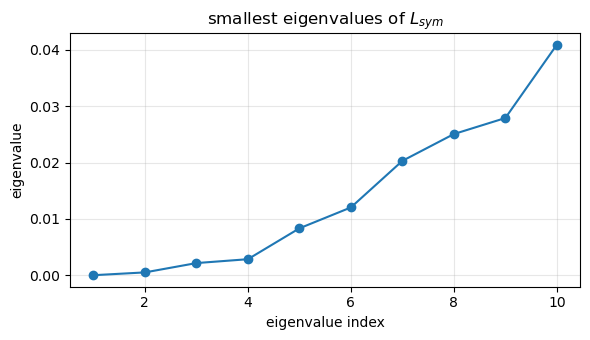

In [5]:
D_inv_sqrt = np.diag(1.0 / np.sqrt(d))
Lsym = np.eye(len(X)) - D_inv_sqrt @ W @ D_inv_sqrt

evals, evecs = eigh(Lsym)
print('ten smallest eigenvalues:')
print(np.round(evals[:10], 6))

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, 11), evals[:10], marker='o')
plt.xlabel('eigenvalue index')
plt.ylabel('eigenvalue')
plt.title('smallest eigenvalues of $L_{sym}$')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Spectral coordinates and clustering

Take the first two eigenvectors of $L_{\rm sym}$, including the zero-eigenvalue direction. Normalize each row to unit length and apply $k$-means to these rows.

Signs and rotations of an eigenbasis can change the displayed coordinates without changing their pairwise distances.

In [6]:
U = evecs[:, :2]
row_norm = np.linalg.norm(U, axis=1, keepdims=True)
Y = U / row_norm

kmeans_spec = KMeans(n_clusters=2, n_init=20, random_state=random_state)
labels_spec = kmeans_spec.fit_predict(Y)
acc_spec = max(
    np.mean(labels_spec == labels),
    np.mean(1 - labels_spec == labels),
)
print(f"spectral clustering accuracy: {acc_spec:.3f}")
if np.mean(labels_spec == labels) < 0.5:
    labels_spec = 1 - labels_spec


spectral clustering accuracy: 1.000


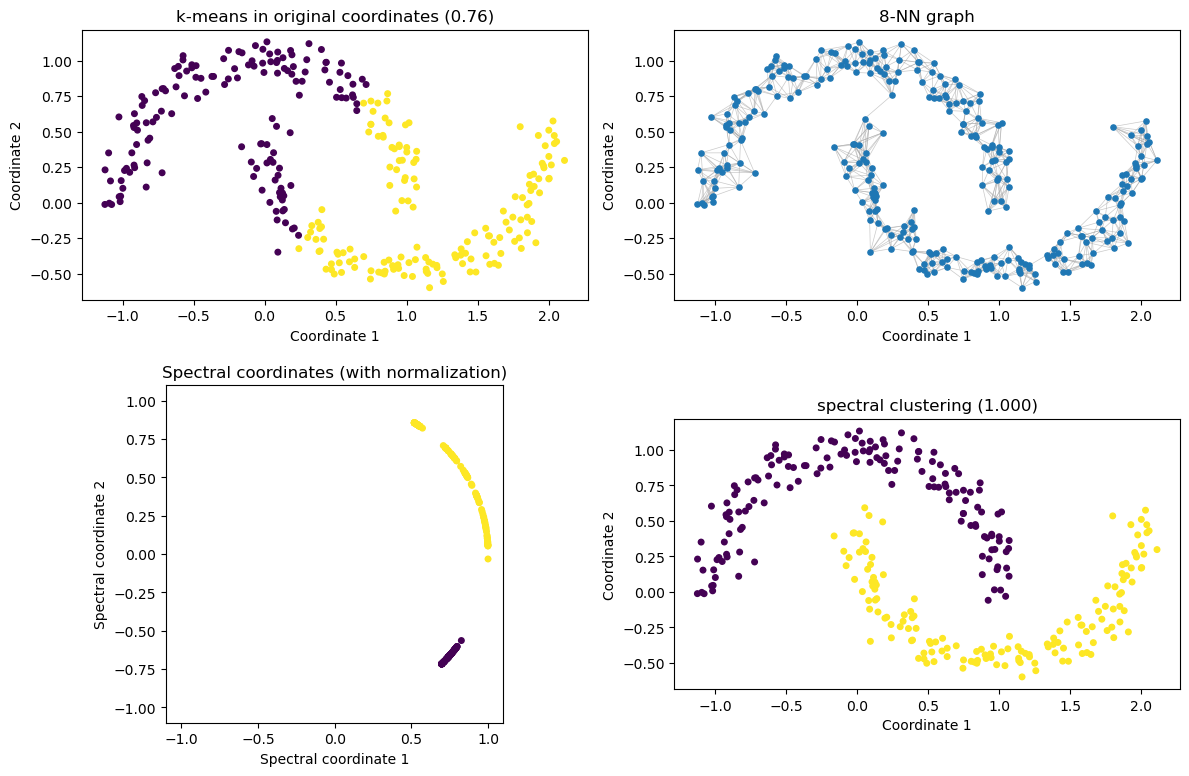

In [7]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(2, 2, 1)
ax.scatter(X[:,0], X[:,1], c=labels_kmeans, cmap="viridis", vmin=0, vmax=1, s=16)
ax.set_aspect('equal')
ax.set_xlabel('Coordinate 1')
ax.set_ylabel('Coordinate 2')
ax.set_title(f'k-means in original coordinates ({acc_kmeans:.2f})')

ax = fig.add_subplot(2, 2, 2)
plot_graph(X, W, ax, f'{k}-NN graph')

ax = fig.add_subplot(2, 2, 3)
ax.scatter(Y[:,0], Y[:,1], c=labels, cmap="viridis", vmin=0, vmax=1, s=16)
ax.set_aspect('equal')
ax.set_xlabel('Coordinate 1')
ax.set_ylabel('Coordinate 2')
ax.set_title('Spectral coordinates (with normalization)')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('Spectral coordinate 1')
ax.set_ylabel('Spectral coordinate 2')

ax = fig.add_subplot(2, 2, 4)
ax.scatter(X[:,0], X[:,1], c=labels_spec, cmap="viridis", vmin=0, vmax=1, s=16)
ax.set_aspect('equal')
ax.set_xlabel('Coordinate 1')
ax.set_ylabel('Coordinate 2')
ax.set_title(f'spectral clustering ({acc_spec:.3f})')

plt.tight_layout()
plt.show()


### Changing the number of neighbors

Keep the data fixed and compare $k=5,8,20$. Small neighborhoods can fragment a moon; large neighborhoods can connect the moons. Check graph connectivity together with clustering accuracy.

The top row shows each neighborhood graph; the bottom row shows the predicted clusters and their accuracy. If the graph has more than two connected components, we skip the two-cluster embedding and report accuracy as N/A: selecting just two eigenvectors from a larger zero-eigenspace would make the result depend on an arbitrary choice of eigenbasis.


k= 5: 3 components; accuracy N/A; reconsider the graph before two-cluster embedding
k= 8: numerical zero eigenvalues=1, spectral clustering accuracy=1.000


k=20: numerical zero eigenvalues=1, spectral clustering accuracy=0.900


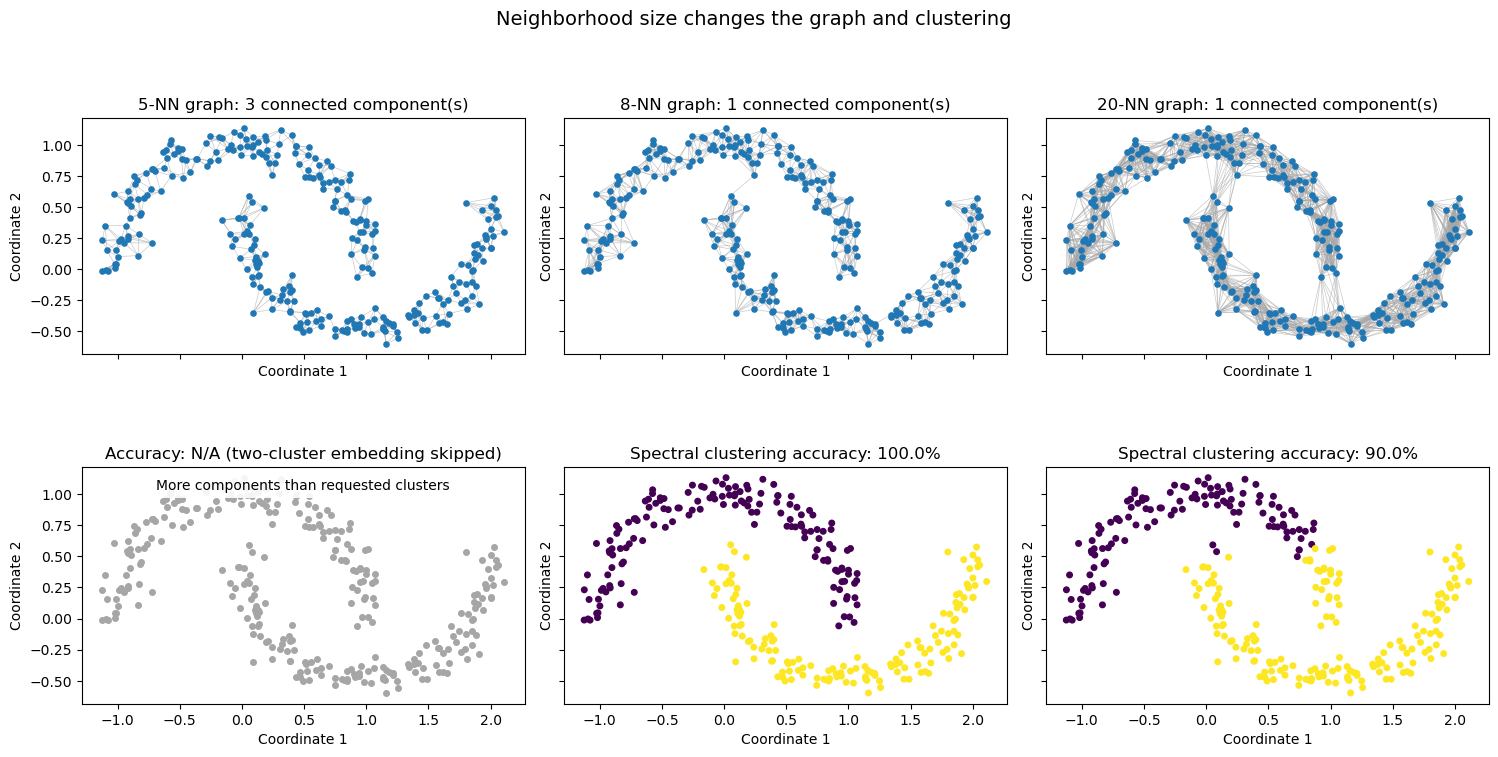

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for column, k_try in enumerate([5, 8, 20]):
    A_try = kneighbors_graph(X, n_neighbors=k_try, mode='connectivity', include_self=False)
    W_try = A_try.maximum(A_try.T).toarray()
    d_try = W_try.sum(axis=1)
    L_try = np.eye(len(X)) - np.diag(1/np.sqrt(d_try)) @ W_try @ np.diag(1/np.sqrt(d_try))
    vals_try, vecs_try = eigh(L_try)
    components_try = connected_components(W_try, directed=False, return_labels=False)

    plot_graph(X, W_try, axes[0, column],
               f'{k_try}-NN graph: {components_try} connected component(s)')
    ax = axes[1, column]
    ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2')
    ax.set_aspect('equal', adjustable='box')

    if components_try > 2:
        print(f"k={k_try:2d}: {components_try} components; accuracy N/A; "
              "reconsider the graph before two-cluster embedding")
        ax.scatter(X[:, 0], X[:, 1], s=16, color='0.65')
        ax.set_title('Accuracy: N/A (two-cluster embedding skipped)')
        ax.text(0.5, 0.95, 'More components than requested clusters',
                transform=ax.transAxes, ha='center', va='top', fontsize=10,
                bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'))
        continue

    U_try = vecs_try[:, :2]
    Y_try = U_try / np.maximum(np.linalg.norm(U_try, axis=1, keepdims=True), 1e-14)
    pred_try = KMeans(n_clusters=2, n_init=20, random_state=random_state).fit_predict(Y_try)
    acc_try = max(np.mean(pred_try == labels), np.mean(1-pred_try == labels))
    n_zero = np.sum(vals_try < 1e-10)
    print(f"k={k_try:2d}: numerical zero eigenvalues={n_zero}, spectral clustering accuracy={acc_try:.3f}")

    # Align cluster colors with the earlier plots only for presentation.
    if np.mean(pred_try == labels) < 0.5:
        pred_try = 1 - pred_try
    ax.scatter(X[:, 0], X[:, 1], c=pred_try, cmap='viridis',
               vmin=0, vmax=1, s=16)
    ax.set_title(f'Spectral clustering accuracy: {acc_try:.1%}')

fig.suptitle('Neighborhood size changes the graph and clustering', fontsize=14)
plt.tight_layout()
plt.show()


#### Interpretation questions

- Why does the neighborhood graph help separate the moons?
- How do the zero eigenvalues relate to the graph components?
- What changes as the number of neighbors increases?
- Why can the spectral coordinates rotate while the clustering stays the same?